# 06 · Backtest 002.1: Pullback na média, nova saída + mais sinais (EURUSD H4 · H1 · M15)

**LHS Quant Lab** · notebook didático · foco em day trading

## De onde viemos
O **002** (pullback na EMA 20/50 do M15 com H4 e H1 a favor, trailing de 3 ATR) foi **reprovado**:
-0,24 R por operação fora da amostra, pior que entrada aleatória, PBO 0,87 e só **0,8 operação por semana**.
Dois problemas ficaram claros:

1. **Saída:** 40% das operações chegavam a +1 R, mas só 25% fechavam no lucro. Com stop inicial de ~1 ATR, o trailing
   de 3 ATR só protege depois de uns +2 R; antes disso o lucro volta inteiro.
2. **Frequência:** as 4 condições do gatilho + 2 tempos gráficos alinhados geram poucos sinais para day trade.

## O que o 002.1 testa (as duas correções juntas)
| Peça | Variações |
|---|---|
| **Saída** | trailing K = 3 (o do 002), **2**, **1,5**, **1** ATR · K = 3 + **stop no zero a zero** ao chegar em +1 R |
| **Entrada: regra do recuo novo** | com (3 barras sem tocar a média) · **sem** (qualquer toque na zona) |
| **Entrada: filtro** | H4 + H1 · **só H1** |
| **Médias do pullback** | 10/50 · 20/50 (as melhores do 002) |

São **40 combinações**. Mais combinações aumentam o risco de achar uma boa por sorte, então a validação é a mesma do
002: consistência por bloco, **PBO** e **walk-forward**.

**Padrão fixado antes de rodar:** 20/50, H4+H1, sem a regra das 3 barras, trailing 1,5 ATR.

## Critério de aprovação (o mesmo do 002)
| # | Critério |
|---|---|
| 1 | ≥ 100 operações fora da amostra |
| 2 | Expectativa > 0 R por operação (líquida) |
| 3 | Fator de lucro > 1,2 |
| 4 | Padrão melhor que entradas aleatórias no mesmo regime (p < 0,05) |
| 5 | PBO < 0,5 |
| 6 | Nenhum ano com drawdown maior que 20% |
| 7 | ≥ 2 operações por semana e intervalo p90 entre dias com operação ≤ 5 dias úteis |

> Educação e pesquisa de método. **Não é recomendação nem sinal de compra ou venda.**

## 1. Configuração
Tudo o que pode ser mudado fica aqui. Os valores `*_PADRAO` são os do setup "de livro", fixados **antes** do teste;
as `GRADE_*` são as alternativas que a otimização vai comparar.

- **Tendência (H4 e H1):** fechamento acima da EMA de tendência, EMA 50 acima dela e EMA de tendência subindo
  (maior que há 20 barras). Baixa é o espelho.
- **Pullback (M15):** EMA rápida acima da lenta; a barra toca a EMA rápida depois de 3 barras sem tocar; fecha de volta
  acima da EMA rápida com candle de alta.
- **Saída:** stop inicial abaixo do fundo do recuo; **trailing Chandelier** (maior máxima desde a entrada − K × ATR);
  opcionalmente **zero a zero** em +1 R;
  sai também se o **H1 perder a tendência** ou às **23h** (day trade, sem swap).

In [ ]:
import itertools
import json
import sys
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

# ---------------- setup ----------------
BACKTEST_ID = "002.1"
SIMBOLO = "EURUSD"
DATA_INICIO_HTF = "2010-01-01"  # H4/H1 (o M15 usa tudo o que tiver)

EMA_TEND_PADRAO = 200  # EMA de tendência no H4 e no H1
EMA_MEDIA_TEND = (
    50  # 2ª condição: EMA 50 acima (alta) / abaixo (baixa) da EMA de tendência
)
INCLINACAO_BARRAS = 20  # EMA de tendência maior (menor) que há 20 barras
PB_PADRAO = (20, 50)  # EMA rápida / lenta do pullback no M15
NOVO_PADRAO = False  # padrão do 002.1: SEM a regra das 3 barras sem toque
FILTRO_PADRAO = "H4+H1"
BARRAS_SEM_TOQUE = 3  # recuo "novo": as 3 barras anteriores não tocaram a EMA rápida

# ---------------- otimização: entrada × saída ----------------
GRADE_TEND = [EMA_TEND_PADRAO]
GRADE_PB = [(10, 50), (20, 50)]
GRADE_NOVO = [True, False]
GRADE_FILTRO = ["H4+H1", "Só H1"]
GRADE_SAIDA = {
    "K3": (3.0, 0.0),
    "K2": (2.0, 0.0),
    "K1.5": (1.5, 0.0),
    "K1": (1.0, 0.0),
    "K3+BE1R": (3.0, 1.0),
}

# ---------------- stop e saída ----------------
ATR_PERIODO = 14
STOP_FOLGA_ATR = 0.1  # stop = fundo das 3 últimas barras − 0,1 ATR
STOP_MIN_ATR, STOP_MAX_ATR = 0.5, 3.0
K_TRAILING = 1.5  # padrão do 002.1 (no 002 era 3)
BE_R = 0.0  # stop no zero a zero ao chegar em +BE_R (0 = desligado)
ALVO_FIXO_R = 2.0  # só na linha de base "alvo fixo"

# ---------------- day trade ----------------
SESSAO = (9, 21)  # horário de FECHAMENTO da barra de sinal (servidor XM)
HORA_ZERAR = 23
HORAS_VIRADA = (22, 23, 0)  # spread alargado na virada do dia
MULT_SPREAD_VIRADA = 1.5

# ---------------- custos e risco ----------------
SLIPPAGE_PONTOS = 2  # por lado
COMISSAO_USD_LOTE = 0.0  # XM Standard = 0 (sensibilidade com 7)
RISCO_POR_TRADE = 0.01  # 1% do capital por operação

# ---------------- validação ----------------
INICIO_OOS = "2023-11-01"
TREINO_MESES, TESTE_MESES = 12, 3
MIN_TRADES_TREINO = 30
N_BLOCOS = 8
N_SIM, N_BOOT, SEED = 1000, 2000, 42

# ---------------- frequência (day trade) ----------------
MIN_TRADES_SEMANA = 2.0
MAX_INTERVALO_P90 = 5  # dias úteis entre dias com operação (percentil 90)

RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
info = info[info["simbolo"] == SIMBOLO].iloc[-1]
PONTO, CONTRATO = float(info["ponto"]), float(info["contrato"])
SLIP = SLIPPAGE_PONTOS * PONTO
print(
    f"{SIMBOLO}: ponto {PONTO} | contrato {CONTRATO:,.0f} | slippage {SLIPPAGE_PONTOS} pontos por lado"
)

EURUSD: ponto 1e-05 | contrato 100,000 | slippage 2 pontos por lado


## 2. Dados e indicadores sem look-ahead
O ponto delicado de usar 3 tempos gráficos: **a barra de H4 que abre às 08:00 só é conhecida às 12:00**.
Se o M15 das 09:00 "visse" essa barra, estaríamos usando o futuro.

A função `no_m15()` leva cada valor do H4/H1 para o M15 **pelo horário de fechamento** (com `merge_asof`):
o M15 que fecha às 12:00 enxerga o H4 que acabou de fechar às 12:00, nunca o H4 ainda em formação.

Os preços do MT5 são de **bid**. Compra entra no **ask** (bid + spread) e venda sai no ask; por isso o spread de cada
barra entra no motor, multiplicado por 1,5 na virada do dia.

In [ ]:
def carregar(tf, inicio=None):
    df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index()
    return df.loc[inicio:] if inicio else df


def ema(s, n):
    return s.ewm(span=n, adjust=False).mean()


def calc_atr(df, n=ATR_PERIODO):
    h, l, c = df["maxima"], df["minima"], df["fechamento"]
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(
        axis=1
    )
    return tr.ewm(alpha=1 / n, adjust=False).mean()


def tendencia(df, n_tend):
    """+1 alta, -1 baixa, 0 sem tendência definida (na barra fechada)."""
    c = df["fechamento"]
    et, e50 = ema(c, n_tend), ema(c, EMA_MEDIA_TEND)
    alta = (c > et) & (e50 > et) & (et > et.shift(INCLINACAO_BARRAS))
    baixa = (c < et) & (e50 < et) & (et < et.shift(INCLINACAO_BARRAS))
    return pd.Series(np.select([alta, baixa], [1, -1], 0), index=df.index)


H4, H1, M15 = (
    carregar("H4", DATA_INICIO_HTF),
    carregar("H1", DATA_INICIO_HTF),
    carregar("M15"),
)
DUR = {
    "H4": pd.Timedelta(hours=4),
    "H1": pd.Timedelta(hours=1),
    "M15": pd.Timedelta(minutes=15),
}
IDX = M15.index
FECHA = IDX + DUR["M15"]


def no_m15(serie, tf):
    """Valor do H4/H1 disponível no fechamento de cada M15 (só barras do H4/H1 já fechadas)."""
    dir_ = pd.DataFrame({"t": serie.index + DUR[tf], "v": serie.to_numpy()})
    m = pd.merge_asof(pd.DataFrame({"t": FECHA}), dir_, on="t", direction="backward")
    return m["v"].fillna(0).to_numpy(np.int64)


TEND = {
    (tf, n): no_m15(tendencia(df, n), tf)
    for tf, df in [("H4", H4), ("H1", H1)]
    for n in GRADE_TEND
}

dia = IDX.normalize()
ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
mult = np.where(np.isin(IDX.hour, HORAS_VIRADA), MULT_SPREAD_VIRADA, 1.0)
A = {
    "o": M15["abertura"].to_numpy(float),
    "h": M15["maxima"].to_numpy(float),
    "l": M15["minima"].to_numpy(float),
    "c": M15["fechamento"].to_numpy(float),
    "spr": M15["spread"].to_numpy(float) * PONTO * mult,
    "atr": calc_atr(M15).to_numpy(float),
    "pode": np.asarray((FECHA.hour >= SESSAO[0]) & (FECHA.hour < SESSAO[1])),
    "zerar": np.asarray((FECHA.hour >= HORA_ZERAR) | ultimo_do_dia),
}
ZEROS = np.zeros(len(IDX), np.int64)
INI, FIM = IDX[0], IDX[-1]

for nome, df in [("H4", H4), ("H1", H1), ("M15", M15)]:
    print(
        f"{nome:>3}: {len(df):>7,} barras | {df.index[0]:%Y-%m-%d} → {df.index[-1]:%Y-%m-%d}"
    )
print(
    f"Spread mediano no M15: {M15['spread'].median():.0f} pontos ({M15['spread'].median() * PONTO / 0.0001:.1f} pip)"
)
h4, h1 = TEND[("H4", EMA_TEND_PADRAO)], TEND[("H1", EMA_TEND_PADRAO)]
print(
    f"Tempo com H4 e H1 alinhados (EMA {EMA_TEND_PADRAO}): alta {np.mean((h4 == 1) & (h1 == 1)):.0%} | "
    f"baixa {np.mean((h4 == -1) & (h1 == -1)):.0%} | fora {np.mean(~(((h4 == 1) & (h1 == 1)) | ((h4 == -1) & (h1 == -1)))):.0%}"
)

 H4:  26,119 barras | 2010-01-04 → 2026-10-16
 H1: 100,017 barras | 2010-09-02 → 2026-10-16
M15: 100,072 barras | 2022-10-06 → 2026-10-16
Spread mediano no M15: 17 pontos (1.7 pip)
Tempo com H4 e H1 alinhados (EMA 200): alta 33% | baixa 27% | fora 40%


## 3. O gatilho do pullback no M15
Para cada par de médias (rápida, lenta), a compra no fechamento da barra *t* exige:
1. EMA rápida > EMA lenta (o M15 também está subindo)
2. **Recuo novo** *(opcional no 002.1)*: as 3 barras anteriores **não** tocaram a EMA rápida
3. A mínima de *t* **toca** a EMA rápida
4. *t* fecha **de volta acima** da EMA rápida, com candle de alta (o retorno à tendência)

A venda é o espelho. O filtro de H4 + H1 é aplicado depois, em `sinal_grupo()`, e assim dá para ligar e desligar
cada peça na comparação da seção 8.

In [ ]:
def gatilhos(rap, lenta, novo=True):
    c, o, h, l = M15["fechamento"], M15["abertura"], M15["maxima"], M15["minima"]
    ef, es = ema(c, rap), ema(c, lenta)
    toque_c, toque_v = (l <= ef), (h >= ef)
    novo_c = toque_c.astype(float).shift(1).rolling(BARRAS_SEM_TOQUE).sum() == 0
    novo_v = toque_v.astype(float).shift(1).rolling(BARRAS_SEM_TOQUE).sum() == 0
    if not novo:  # sem a regra: qualquer toque na zona vale
        novo_c = novo_v = True
    compra = (ef > es) & novo_c & toque_c & (c > ef) & (c > o)
    venda = (ef < es) & novo_v & toque_v & (c < ef) & (c < o)
    return compra.to_numpy(), venda.to_numpy()


def sinal_grupo(compra, venda, h4, h1, grupo="H4+H1"):
    """+1/-1 onde o gatilho e o filtro do grupo concordam."""
    up, dn = {
        "H4+H1": ((h4 == 1) & (h1 == 1), (h4 == -1) & (h1 == -1)),
        "Sem filtro": (np.ones_like(compra), np.ones_like(venda)),
        "Só H4": (h4 == 1, h4 == -1),
        "Só H1": (h1 == 1, h1 == -1),
        "Contra a tendência": ((h4 == -1) & (h1 == -1), (h4 == 1) & (h1 == 1)),
        "H4 e H1 discordam": (h4 * h1 == -1, h4 * h1 == -1),
    }[grupo]
    return np.where(compra & up, 1, np.where(venda & dn, -1, 0)).astype(np.int64)


compra, venda = gatilhos(*PB_PADRAO, novo=NOVO_PADRAO)
s = sinal_grupo(compra, venda, h4, h1, FILTRO_PADRAO)
c_old, v_old = gatilhos(*PB_PADRAO, novo=True)
print(
    f"Sem a regra das 3 barras: {(c_old.sum() + v_old.sum()):,} → {(compra.sum() + venda.sum()):,} gatilhos"
)
print(
    f"Médias {PB_PADRAO}: gatilhos de compra {compra.sum():,} | venda {venda.sum():,} | "
    f"com H4+H1 a favor {np.count_nonzero(s):,} | dentro da sessão {np.count_nonzero(s & A['pode']):,}"
)

Sem a regra das 3 barras: 910 → 10,898 gatilhos
Médias (20, 50): gatilhos de compra 5,413 | venda 5,485 | com H4+H1 a favor 3,854 | dentro da sessão 1,990


## 4. O motor (barra a barra, com numba)
Com trailing stop, cada barra depende do que aconteceu antes, então o motor é um laço compilado com **numba**.

**Regras de execução, na ordem:**
- **Sinal** no fechamento da barra *t* → entrada na **abertura de *t+1*** (compra no ask + slippage).
- **Stop inicial:** fundo das 3 últimas barras − 0,1 ATR. Se ficar a menos de 0,5 ou mais de 3 ATR, **não entra**.
- **Durante a barra:** se a mínima toca o stop, sai no stop (ou na abertura, se abriu além dele). Se stop e alvo
  cabem na mesma barra, conta o **stop** (conservador).
- **No fechamento:** sobe o trailing (maior máxima desde a entrada − K × ATR); se a máxima já chegou a +1 R, o stop
  vai para o **zero a zero** (variação BE); sai se o **H1 perdeu a tendência** ou
  se chegou a hora de **zerar** (23h / última barra do dia).
- **Resultado em R:** lucro ÷ risco inicial. `R` é líquido (spread, slippage, comissão); `R_bruto` é a mesma
  operação sem nenhum custo.

In [ ]:
@njit(cache=True)
def motor(
    o,
    h,
    l,
    c,
    spr,
    atr,
    sinal,
    pode,
    zerar,
    saida_dir,
    usar_saida_dir,
    k,
    alvo_r,
    be_r,
    folga,
    smin,
    smax,
    slip,
    comis,
):
    n = len(c)
    cap = n // 4 + 10
    ent = np.empty(cap, np.int64)
    sai = np.empty(cap, np.int64)
    dire = np.empty(cap, np.int64)
    mot = np.empty(cap, np.int64)
    rl = np.empty(cap)
    rb = np.empty(cap)
    nt, pos = 0, 0
    stop, alvo, extremo, e_l, e_b, risco = 0.0, 0.0, 0.0, 0.0, 0.0, 1.0
    for t in range(3, n):
        if pos != 0:
            px, m = 0.0, 0
            # 1) durante a barra: stop primeiro (conservador), depois alvo
            if pos == 1:
                if l[t] <= stop:
                    px, m = min(o[t], stop), 1
                elif alvo_r > 0 and h[t] >= alvo:
                    px, m = max(o[t], alvo), 4
            else:
                if h[t] + spr[t] >= stop:
                    px, m = max(o[t] + spr[t], stop), 1
                elif alvo_r > 0 and l[t] + spr[t] <= alvo:
                    px, m = min(o[t] + spr[t], alvo), 4
            # 2) no fechamento: trailing, tendência do H1, fim do dia
            if m == 0:
                if pos == 1:
                    extremo = max(extremo, h[t])
                    if k > 0:
                        stop = max(stop, extremo - k * atr[t])
                    if be_r > 0 and extremo - e_l >= be_r * risco:
                        stop = max(stop, e_l + slip)
                else:
                    extremo = min(extremo, l[t])
                    if k > 0:
                        stop = min(stop, extremo + k * atr[t])
                    if be_r > 0 and e_l - (extremo + spr[t]) >= be_r * risco:
                        stop = min(stop, e_l - slip)
                if usar_saida_dir and saida_dir[t] != pos:
                    m = 2
                elif zerar[t]:
                    m = 3
                elif t == n - 1:
                    m = 5
                if m != 0:
                    px = c[t] if pos == 1 else c[t] + spr[t]
            if m != 0:
                if pos == 1:
                    x_b, x_l = px, px - slip
                else:
                    x_b, x_l = px - spr[t], px + slip
                rb[nt] = pos * (x_b - e_b) / risco
                rl[nt] = (pos * (x_l - e_l) - comis) / risco
                sai[nt], mot[nt] = t, m
                nt += 1
                pos = 0
            continue
        # 3) sem posição: novo sinal?
        if sinal[t] == 0 or not pode[t] or zerar[t] or t + 1 >= n:
            continue
        d = sinal[t]
        if d == 1:
            s0 = min(l[t], min(l[t - 1], l[t - 2])) - folga * atr[t]
        else:
            s0 = max(h[t], max(h[t - 1], h[t - 2])) + folga * atr[t] + spr[t]
        dist = abs(c[t] - s0)
        if dist < smin * atr[t] or dist > smax * atr[t]:
            continue
        j = t + 1
        if d == 1:
            if o[j] <= s0:
                continue
            e_b, e_l = o[j], o[j] + spr[j] + slip
        else:
            if o[j] + spr[j] >= s0:
                continue
            e_b, e_l = o[j], o[j] - slip
        risco = abs(e_l - s0)
        if risco <= 0:
            continue
        pos, stop, extremo = d, s0, o[j]
        alvo = e_l + d * alvo_r * risco
        ent[nt], dire[nt] = j, d
    return ent[:nt], sai[:nt], dire[:nt], mot[:nt], rl[:nt], rb[:nt]


MOTIVOS = np.array(
    ["", "stop", "H1 perdeu tendência", "fim do dia", "alvo", "fim dos dados"]
)


def rodar(
    sinal,
    saida_dir=None,
    k=K_TRAILING,
    alvo_r=0.0,
    be_r=BE_R,
    comissao=COMISSAO_USD_LOTE,
):
    usar = saida_dir is not None
    ent, sai, d, m, rl, rb = motor(
        A["o"],
        A["h"],
        A["l"],
        A["c"],
        A["spr"],
        A["atr"],
        np.asarray(sinal, np.int64),
        A["pode"],
        A["zerar"],
        saida_dir if usar else ZEROS,
        usar,
        float(k),
        float(alvo_r),
        float(be_r),
        STOP_FOLGA_ATR,
        STOP_MIN_ATR,
        STOP_MAX_ATR,
        SLIP,
        comissao / CONTRATO,
    )
    return pd.DataFrame(
        {
            "entrada": IDX[ent],
            "saida": IDX[sai],
            "direcao": d,
            "motivo": MOTIVOS[m],
            "R": rl,
            "R_bruto": rb,
            "barras": sai - ent + 1,
        }
    )


def estrategia(
    n_tend=EMA_TEND_PADRAO, pb=PB_PADRAO, novo=NOVO_PADRAO, filtro=FILTRO_PADRAO, **kw
):
    """O setup completo: gatilho do pullback + filtro de tendência + saída se o H1 perder a tendência."""
    cp, vd = gatilhos(*pb, novo=novo)
    h4_, h1_ = TEND[("H4", n_tend)], TEND[("H1", n_tend)]
    return rodar(sinal_grupo(cp, vd, h4_, h1_, filtro), saida_dir=h1_, **kw)

### Métricas
Tudo em **R** (múltiplos do risco), o que permite comparar períodos e parâmetros. A curva de capital usa
**1% de risco por operação**. Para day trade, entram também as métricas de **frequência**:
- **Trades/semana** e **% de dias úteis com operação**
- **Intervalo p90 / máx.:** dias úteis entre um dia com operação e o próximo (1 = operou no dia útil seguinte).
  O p90 diz "em 90% das vezes, o próximo sinal veio em até X dias úteis".

In [ ]:
def frequencia(tr, ini, fim):
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    d_ent = np.sort(
        tr["entrada"].dt.normalize().unique().to_numpy().astype("datetime64[D]")
    )
    pontos = np.concatenate(
        [
            [np.datetime64(ini.normalize(), "D")],
            d_ent,
            [np.datetime64(fim.normalize(), "D")],
        ]
    )
    gaps = np.busday_count(pontos[:-1], pontos[1:])
    gaps = gaps[gaps > 0] if (gaps > 0).any() else np.array([len(dias)])
    return {
        "Trades/semana": len(tr) / (len(dias) / 5),
        "% dias úteis com trade": len(d_ent) / len(dias) * 100,
        "Intervalo p90 (dias úteis)": float(np.percentile(gaps, 90)),
        "Intervalo máx. (dias úteis)": int(gaps.max()),
    }


def metricas(tr, ini=None, fim=None):
    ini, fim = ini or INI, fim or FIM
    tr = tr[(tr["entrada"] >= ini) & (tr["entrada"] <= fim)]
    if len(tr) == 0:
        return pd.Series({"Nº trades": 0})
    r = tr["R"]
    g, p = r[r > 0], r[r <= 0]
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    ret_d = (
        tr.groupby(tr["saida"].dt.normalize())["R"].sum() * RISCO_POR_TRADE
    ).reindex(dias, fill_value=0.0)
    neg = np.minimum(ret_d, 0)
    return pd.Series(
        {
            "Nº trades": len(tr),
            "Win rate %": len(g) / len(tr) * 100,
            "Payoff": g.mean() / abs(p.mean()) if len(p) and len(g) else np.nan,
            "Expectativa R": r.mean(),
            "Expectativa R sem custos": tr["R_bruto"].mean(),
            "Fator de lucro": g.sum() / abs(p.sum()) if len(p) else np.nan,
            "Total R": r.sum(),
            "Retorno % (1% risco)": (cap.iloc[-1] - 1) * 100,
            "Máx. drawdown %": (cap / cap.cummax() - 1).min() * 100,
            "Sharpe": ret_d.mean() / ret_d.std() * np.sqrt(252)
            if ret_d.std() > 0
            else np.nan,
            "Sortino": ret_d.mean() / np.sqrt((neg**2).mean()) * np.sqrt(252)
            if (neg < 0).any()
            else np.nan,
            **frequencia(tr, ini, fim),
        }
    )


def boot_ic(r, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    r = np.asarray(r)
    medias = r[rng.integers(0, len(r), (n, len(r)))].mean(axis=1)
    return np.percentile(medias, [2.5, 97.5])

## 5. Resultado com os parâmetros padrão (sem otimização)
EMA 200 no H4/H1, pullback na EMA 20/50 do M15 **sem** a regra das 3 barras, trailing de **1,5 ATR**.
Como **nada foi ajustado**, o período inteiro
vale como teste. Compare **sem custos × líquido**: no M15, o spread costuma comer boa parte da vantagem.

In [6]:
TR_PADRAO = estrategia()
m_padrao = metricas(TR_PADRAO)
display(m_padrao.to_frame("Padrão 002.1").round(3))
print("Como as operações terminaram (%):")
display((TR_PADRAO["motivo"].value_counts(normalize=True) * 100).round(1).to_frame("%"))

,Padrão 002.1
Nº trades,"1,273.000"
Win rate %,28.280
Payoff,1.327
Expectativa R,-0.219
Expectativa R sem custos,-0.011
Fator de lucro,0.523
Total R,-278.911
Retorno % (1% risco),-94.183
Máx. drawdown %,-94.156
Sharpe,-3.817


Como as operações terminaram (%):


,%
motivo,
stop,97.300
fim do dia,2.700


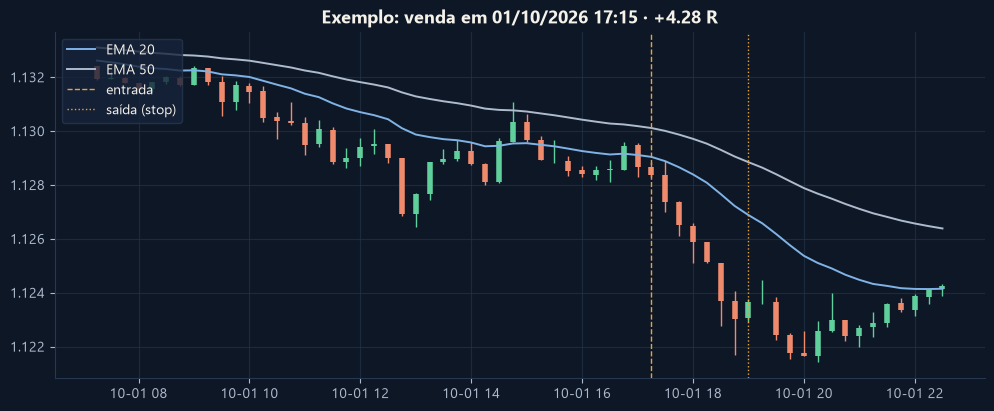

In [ ]:
# uma operação de exemplo: confira visualmente que a entrada é no retorno à média, a favor do H4/H1
ef_, es_ = ema(M15["fechamento"], PB_PADRAO[0]), ema(M15["fechamento"], PB_PADRAO[1])
ex = TR_PADRAO[(TR_PADRAO["R"] > 1)].iloc[-1]
i0, i1 = IDX.get_loc(ex["entrada"]) - 40, IDX.get_loc(ex["saida"]) + 15
j = M15.iloc[i0:i1]
fig, ax = plt.subplots(figsize=(12, 4.5))
cor = np.where(j["fechamento"] >= j["abertura"], CORES["positivo"], CORES["negativo"])
ax.vlines(j.index, j["minima"], j["maxima"], color=cor, lw=1)
ax.vlines(
    j.index,
    j[["abertura", "fechamento"]].min(axis=1),
    j[["abertura", "fechamento"]].max(axis=1),
    color=cor,
    lw=4,
)
ax.plot(
    j.index,
    ef_.iloc[i0:i1],
    color=CORES["secundaria"],
    lw=1.4,
    label=f"EMA {PB_PADRAO[0]}",
)
ax.plot(
    j.index,
    es_.iloc[i0:i1],
    color=CORES["texto_suave"],
    lw=1.4,
    label=f"EMA {PB_PADRAO[1]}",
)
ax.axvline(ex["entrada"], color=CORES["primaria"], ls="--", lw=1, label="entrada")
ax.axvline(
    ex["saida"], color=CORES["primaria"], ls=":", lw=1, label=f"saída ({ex['motivo']})"
)
ax.set_title(
    f"Exemplo: {'compra' if ex['direcao'] == 1 else 'venda'} em {ex['entrada']:%d/%m/%Y %H:%M} · {ex['R']:+.2f} R"
)
ax.legend(loc="upper left")
plt.show()

## 6. As 40 combinações (período todo)
> ⚠️ **Esta tabela sozinha não serve para escolher.** Com 40 tentativas, a melhor sempre parece boa, em parte por
> sorte. Ela mostra **qual peça move o resultado**: se uma saída melhora *todas* as entradas (efeito consistente)
> ou só uma (provável acaso). A escolha honesta vem nas seções 7 e 8.

,Nº trades,Trades/semana,Intervalo p90 (dias úteis),Win rate %,Payoff,Expectativa R,Expectativa R sem custos,Fator de lucro,Máx. drawdown %,Sharpe
10/50 · novo · H4+H1 · K1.5,223.000,1.060,15.000,33.184,1.574,-0.100,0.144,0.782,-31.059,-0.674
10/50 · novo · H4+H1 · K2,216.000,1.027,15.000,31.019,1.697,-0.126,0.119,0.763,-34.898,-0.720
10/50 · novo · Só H1 · K1.5,328.000,1.559,9.000,31.707,1.555,-0.132,0.115,0.722,-44.075,-1.072
10/50 · novo · H4+H1 · K3,209.000,0.993,15.000,27.751,2.037,-0.138,0.110,0.782,-43.082,-0.575
10/50 · novo · H4+H1 · K1,227.000,1.079,15.000,34.361,1.232,-0.147,0.090,0.645,-34.962,-1.230
10/50 · novo · Só H1 · K1,332.000,1.578,9.000,32.229,1.263,-0.167,0.075,0.601,-47.625,-1.680
10/50 · novo · Só H1 · K2,320.000,1.521,9.000,28.125,1.717,-0.182,0.066,0.672,-52.193,-1.289
10/50 · novo · H4+H1 · K3+BE1R,211.000,1.003,15.000,23.697,2.106,-0.190,0.056,0.654,-43.951,-1.064
10/50 · zona · H4+H1 · K1.5,"1,848.000",8.783,4.000,28.950,1.414,-0.191,0.020,0.576,-97.431,-4.160
10/50 · novo · Só H1 · K3,311.000,1.478,9.000,26.045,1.984,-0.197,0.054,0.699,-57.575,-1.073


,Expectativa R,Trades/semana
saída,,
K1,-0.220,5.554
K1.5,-0.206,5.094
K2,-0.238,4.532
K3,-0.263,3.659
K3+BE1R,-0.251,3.808


,Expectativa R,Trades/semana
recuo,,
novo,-0.250,1.030
zona,-0.220,8.029


,Expectativa R,Trades/semana
filtro,,
H4+H1,-0.238,3.674
Só H1,-0.233,5.385


,Expectativa R,Trades/semana
médias,,
10/50,-0.184,5.294
20/50,-0.287,3.765


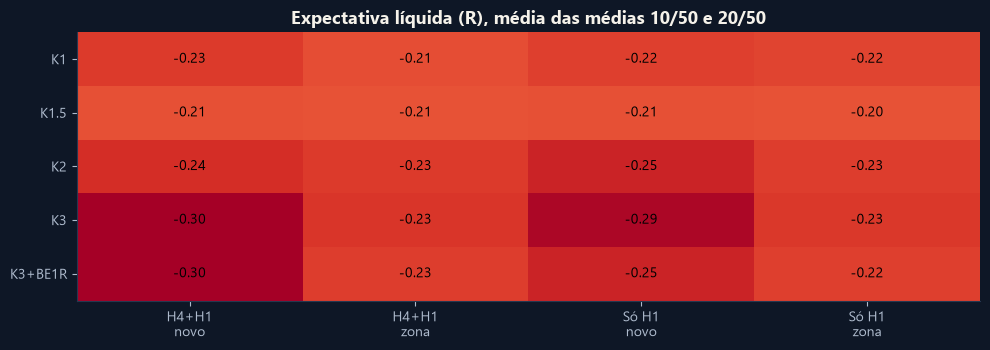

In [8]:
def nome_c(pb, novo, filtro, saida):
    return f"{pb[0]}/{pb[1]} · {'novo' if novo else 'zona'} · {filtro} · {saida}"


COMBOS = list(itertools.product(GRADE_PB, GRADE_NOVO, GRADE_FILTRO, GRADE_SAIDA))
TR_C = {
    nome_c(pb, nv, f, s): estrategia(
        pb=pb, novo=nv, filtro=f, k=GRADE_SAIDA[s][0], be_r=GRADE_SAIDA[s][1]
    )
    for pb, nv, f, s in COMBOS
}
NOME_PADRAO = nome_c(PB_PADRAO, NOVO_PADRAO, FILTRO_PADRAO, "K1.5")
grade = pd.DataFrame({n: metricas(tr) for n, tr in TR_C.items()}).T
cols = [
    "Nº trades",
    "Trades/semana",
    "Intervalo p90 (dias úteis)",
    "Win rate %",
    "Payoff",
    "Expectativa R",
    "Expectativa R sem custos",
    "Fator de lucro",
    "Máx. drawdown %",
    "Sharpe",
]
display(grade[cols].sort_values("Expectativa R", ascending=False).head(15).round(3))

# efeito de cada peça: média da expectativa sobre todas as outras combinações
pecas = pd.DataFrame(
    [
        {
            "médias": f"{pb[0]}/{pb[1]}",
            "recuo": "novo" if nv else "zona",
            "filtro": f,
            "saída": s,
        }
        for pb, nv, f, s in COMBOS
    ],
    index=grade.index,
).join(grade[["Expectativa R", "Trades/semana"]])
for peca in ["saída", "recuo", "filtro", "médias"]:
    display(pecas.groupby(peca)[["Expectativa R", "Trades/semana"]].mean().round(3))

piv = pecas.pivot_table(
    index="saída", columns=["filtro", "recuo"], values="Expectativa R", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.imshow(piv, cmap="RdYlGn", vmin=-0.3, vmax=0.3, aspect="auto")
for (a_, b_), v in np.ndenumerate(piv.to_numpy()):
    ax.text(b_, a_, f"{v:+.2f}", ha="center", va="center", color="black", fontsize=10)
ax.set_yticks(range(len(piv)), piv.index)
ax.set_xticks(range(piv.shape[1]), [f"{f}\n{r}" for f, r in piv.columns])
ax.set_title("Expectativa líquida (R), média das médias 10/50 e 20/50")
ax.grid(False)
plt.tight_layout()
plt.show()

## 7. A otimização é robusta? Teste em blocos
Três olhares diferentes contra o sobreajuste:

**7.1 Consistência por bloco.** O período do M15 é dividido em **8 blocos** de mesmo tamanho (~6 meses). Uma
combinação robusta ganha na **maioria** dos blocos, não só em um bloco excepcional.

**7.2 PBO: probabilidade de sobreajuste (Bailey et al., CSCV).** Juntamos os 8 blocos de todas as formas possíveis em
**4 de treino + 4 de teste** (70 divisões). Em cada uma, escolhemos a melhor combinação no treino e vemos **em que
posição ela fica no teste**. Se a "campeã do treino" cai para a metade de baixo no teste em boa parte das vezes, a
otimização está escolhendo sorte. **PBO < 0,5** é o mínimo; perto de 0 é ótimo.

**7.3 Walk-forward.** Simula o uso real: a cada 3 meses, escolhe as médias com os **12 meses anteriores** e opera os 3
meses seguintes sem olhar o futuro. Concorrem as combinações com ≥ 30 operações no treino; as que têm ≥ 2
operações/semana têm prioridade (se nenhuma tiver, a janela fica marcada).

In [9]:
# 7.1 consistência por bloco
bordas = pd.date_range(INI, FIM, periods=N_BLOCOS + 1)
blocos = pd.DataFrame(
    {
        n: [
            tr.loc[(tr["entrada"] >= a) & (tr["entrada"] < b), "R"].sum()
            for a, b in zip(bordas[:-1], bordas[1:])
        ]
        for n, tr in TR_C.items()
    },
    index=[f"{a:%m/%y}–{b:%m/%y}" for a, b in zip(bordas[:-1], bordas[1:])],
).T
blocos["Blocos positivos"] = (blocos > 0).sum(axis=1).astype(str) + f"/{N_BLOCOS}"
print("Total de R por bloco (líquido):")
display(blocos.sort_values("Blocos positivos", ascending=False).round(1))

Total de R por bloco (líquido):


,10/22–04/23,04/23–10/23,10/23–04/24,04/24–10/24,10/24–04/25,04/25–10/25,10/25–04/26,04/26–10/26,Blocos positivos
10/50 · novo · H4+H1 · K3,3.900,-1.000,-8.400,-7.700,-10.100,-10.900,2.800,2.800,3/8
10/50 · novo · H4+H1 · K2,1.500,6.900,-6.200,-5.800,-7.800,-11.400,2.400,-6.900,3/8
10/50 · novo · H4+H1 · K1.5,2.500,8.100,-3.300,-3.100,-9.900,-9.700,3.700,-10.700,3/8
10/50 · novo · H4+H1 · K3+BE1R,1.800,1.900,-11.200,-5.300,-10.900,-8.700,1.000,-8.600,3/8
10/50 · novo · Só H1 · K3,2.700,1.000,-20.900,-10.000,-15.400,-9.900,-6.400,-2.300,2/8
10/50 · novo · Só H1 · K2,1.600,4.200,-15.200,-5.200,-11.500,-8.600,-9.900,-13.700,2/8
10/50 · novo · Só H1 · K1.5,2.600,7.100,-9.300,-1.300,-10.900,-8.100,-5.900,-17.600,2/8
10/50 · novo · Só H1 · K1,-4.900,1.000,-10.400,2.100,-10.400,-7.100,-9.500,-16.300,2/8
10/50 · novo · Só H1 · K3+BE1R,1.400,4.200,-17.800,-7.000,-16.300,-7.600,-7.700,-13.600,2/8
20/50 · novo · Só H1 · K3+BE1R,-7.400,-7.400,-14.300,-16.700,1.500,7.700,-9.300,-12.800,2/8


Divisões testadas: 70 (= C(8,4))
PBO = 0.77  → em 77% das divisões a campeã do treino ficou na metade de baixo no teste
Sharpe anual da campeã: treino -2.58 → teste -3.28 (perda típica da otimização)


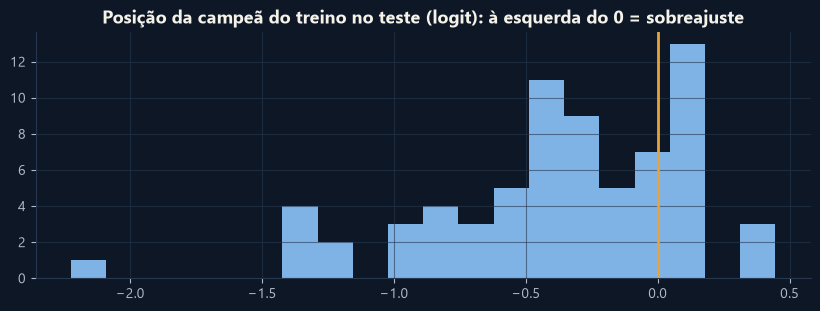

In [10]:
# 7.2 PBO por CSCV (semanas × combinações)
semanas = pd.period_range(INI, FIM, freq="W")
R_sem = pd.DataFrame(
    {
        n: tr.groupby(tr["saida"].dt.to_period("W"))["R"]
        .sum()
        .reindex(semanas, fill_value=0)
        for n, tr in TR_C.items()
    }
)
N_sem = pd.DataFrame(
    {
        n: tr.groupby(tr["entrada"].dt.to_period("W"))["R"]
        .count()
        .reindex(semanas, fill_value=0)
        for n, tr in TR_C.items()
    }
)
partes = np.array_split(np.arange(len(semanas)), N_BLOCOS)
lambdas, deg = [], []
for is_ in itertools.combinations(range(N_BLOCOS), N_BLOCOS // 2):
    i_is = np.concatenate([partes[b] for b in is_])
    i_os = np.concatenate([partes[b] for b in range(N_BLOCOS) if b not in is_])
    sh = lambda ix: R_sem.iloc[ix].mean() / R_sem.iloc[ix].std()
    sh_is, sh_os = sh(i_is), sh(i_os)
    freq_ok = N_sem.iloc[i_is].sum() / len(i_is) >= MIN_TRADES_SEMANA
    cand = sh_is[freq_ok] if freq_ok.any() else sh_is
    melhor = cand.idxmax()
    w = sh_os.rank().loc[melhor] / (len(sh_os) + 1)
    lambdas.append(np.log(w / (1 - w)))
    deg.append((sh_is[melhor], sh_os[melhor]))
lambdas = np.array(lambdas)
PBO = float((lambdas <= 0).mean())
deg = np.array(deg) * np.sqrt(52)
print(f"Divisões testadas: {len(lambdas)} (= C({N_BLOCOS},{N_BLOCOS // 2}))")
print(
    f"PBO = {PBO:.2f}  → em {PBO:.0%} das divisões a campeã do treino ficou na metade de baixo no teste"
)
print(
    f"Sharpe anual da campeã: treino {deg[:, 0].mean():.2f} → teste {deg[:, 1].mean():.2f} (perda típica da otimização)"
)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(lambdas, bins=20, color=CORES["secundaria"])
ax.axvline(0, color=CORES["primaria"], lw=2)
ax.set_title(
    "Posição da campeã do treino no teste (logit): à esquerda do 0 = sobreajuste"
)
plt.show()

In [11]:
# 7.3 walk-forward
def janelas():
    ini, lista = pd.Timestamp(INICIO_OOS), []
    while ini <= FIM:
        fim = ini + pd.DateOffset(months=TESTE_MESES)
        lista.append((ini - pd.DateOffset(months=TREINO_MESES), ini, fim))
        ini = fim
    return lista


linhas, oos = [], []
for tr_ini, te_ini, te_fim in janelas():
    nota = {}
    for n, tr in TR_C.items():
        r = tr.loc[(tr["entrada"] >= tr_ini) & (tr["entrada"] < te_ini), "R"]
        por_sem = len(r) / ((te_ini - tr_ini).days / 7)
        if len(r) >= MIN_TRADES_TREINO and r.std() > 0:
            nota[n] = (
                r.mean() / r.std() * np.sqrt(len(r)),
                por_sem,
            )  # estatística t da expectativa
    rapidas = {n: v for n, v in nota.items() if v[1] >= MIN_TRADES_SEMANA}
    pool = (
        rapidas or nota
    )  # se nenhuma tem a frequência mínima, escolhe entre todas e registra
    escolha = max(pool, key=lambda n: pool[n][0]) if pool else NOME_PADRAO
    tr = TR_C[escolha]
    sel = tr[(tr["entrada"] >= te_ini) & (tr["entrada"] < te_fim)].assign(combo=escolha)
    oos.append(sel)
    linhas.append(
        {
            "teste": f"{te_ini:%Y-%m}",
            "escolha": escolha,
            "t treino": nota.get(escolha, (np.nan,))[0],
            "trades/sem treino": nota.get(escolha, (np.nan, np.nan))[1],
            "freq. mínima ok": bool(rapidas),
            "trades teste": len(sel),
            "R teste": sel["R"].sum(),
        }
    )
WF = pd.DataFrame(linhas)
TR_WF = pd.concat(oos, ignore_index=True)
display(WF.round(2))
print("Combinações escolhidas:", WF["escolha"].value_counts().to_dict())
if not WF["freq. mínima ok"].all():
    print(
        f"⚠️ Em {(~WF['freq. mínima ok']).sum()} de {len(WF)} janelas nenhuma combinação teve ≥ {MIN_TRADES_SEMANA:g} trades/semana no treino"
    )

,teste,escolha,t treino,trades/sem treino,freq. mínima ok,trades teste,R teste
0,2023-11,10/50 · zona · H4+H1 · K3,-2.390,6.310,True,73,-17.450
1,2024-02,10/50 · zona · H4+H1 · K3,-2.370,5.720,True,61,-26.100
2,2024-05,20/50 · zona · H4+H1 · K3,-2.970,4.320,True,47,-7.620
3,2024-08,20/50 · zona · H4+H1 · K3,-3.330,4.020,True,84,-23.350
4,2024-11,20/50 · zona · H4+H1 · K3+BE1R,-2.830,4.650,True,74,-17.990
5,2025-02,20/50 · zona · H4+H1 · K3+BE1R,-2.750,4.840,True,60,-10.900
6,2025-05,20/50 · zona · H4+H1 · K3+BE1R,-2.580,5.160,True,64,-13.800
7,2025-08,20/50 · zona · Só H1 · K3+BE1R,-2.160,7.120,True,75,1.640
8,2025-11,20/50 · zona · Só H1 · K3+BE1R,-1.190,6.420,True,88,-23.400
9,2026-02,20/50 · zona · Só H1 · K3+BE1R,-1.600,6.350,True,85,-26.670


Combinações escolhidas: {'20/50 · zona · H4+H1 · K3+BE1R': 3, '20/50 · zona · Só H1 · K3+BE1R': 3, '10/50 · zona · H4+H1 · K3': 2, '20/50 · zona · H4+H1 · K3': 2, '20/50 · zona · H4+H1 · K2': 2}


## 8. O filtro de H4 + H1 faz diferença?
Gatilho padrão do 002.1 (20/50, zona, trailing 1,5 ATR), mesmas saídas (**sem** a saída pelo H1 para a comparação
ser justa), mudando só o filtro. Período todo. A barra de erro é o **intervalo de confiança de 95%** da
expectativa (bootstrap).

**Como ler:** se a ideia funciona, **H4+H1** deve ficar acima de **Sem filtro** e bem acima de **Contra a
tendência**. Se "Só H1" der o mesmo, a regra mais simples vence (e gera mais sinais).

,Nº trades,Trades/semana,Expectativa R,"IC 2,5%","IC 97,5%",Expectativa R sem custos,Fator de lucro,Win rate %,Máx. drawdown %
H4+H1,"1,273.000",6.050,-0.219,-0.267,-0.169,-0.011,0.523,28.280,-94.156
Sem filtro,"3,682.000",17.500,-0.209,-0.239,-0.179,0.005,0.547,27.784,-99.963
Só H4,"1,673.000",7.952,-0.209,-0.255,-0.164,0.001,0.546,28.571,-97.236
Só H1,"1,875.000",8.912,-0.211,-0.253,-0.170,-0.001,0.537,28.320,-98.224
Contra a tendência,"1,038.000",4.933,-0.201,-0.259,-0.144,0.018,0.564,26.301,-88.976
H4 e H1 discordam,525.000,2.495,-0.167,-0.247,-0.080,0.049,0.622,28.952,-61.605
Alvo fixo 2R (sem trailing),891.000,4.235,-0.265,-0.346,-0.186,-0.056,0.623,27.722,-91.094
Setup completo (com saída pelo H1),"1,273.000",6.050,-0.219,-0.267,-0.169,-0.011,0.523,28.280,-94.156


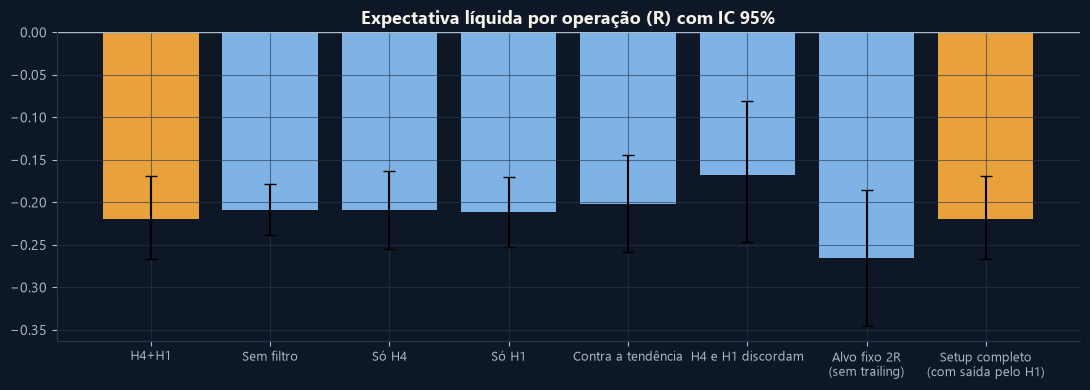

In [12]:
GRUPOS = [
    "H4+H1",
    "Sem filtro",
    "Só H4",
    "Só H1",
    "Contra a tendência",
    "H4 e H1 discordam",
]
TR_G = {g: rodar(sinal_grupo(compra, venda, h4, h1, g)) for g in GRUPOS}
TR_G["Alvo fixo 2R (sem trailing)"] = rodar(
    sinal_grupo(compra, venda, h4, h1, FILTRO_PADRAO), k=0.0, alvo_r=ALVO_FIXO_R
)
TR_G["Setup completo (com saída pelo H1)"] = TR_PADRAO
tab_g = pd.DataFrame({g: metricas(tr) for g, tr in TR_G.items()}).T
ic = pd.DataFrame(
    {g: boot_ic(tr["R"]) for g, tr in TR_G.items() if len(tr) > 10},
    index=["IC 2,5%", "IC 97,5%"],
).T
tab_g = tab_g.join(ic)
display(
    tab_g[
        [
            "Nº trades",
            "Trades/semana",
            "Expectativa R",
            "IC 2,5%",
            "IC 97,5%",
            "Expectativa R sem custos",
            "Fator de lucro",
            "Win rate %",
            "Máx. drawdown %",
        ]
    ].round(3)
)

fig, ax = plt.subplots(figsize=(11, 4))
g_ = tab_g.index[: len(GRUPOS) + 2]
y = tab_g.loc[g_, "Expectativa R"]
err = np.vstack([y - tab_g.loc[g_, "IC 2,5%"], tab_g.loc[g_, "IC 97,5%"] - y])
ax.bar(
    range(len(g_)),
    y,
    yerr=err,
    capsize=4,
    color=[
        CORES["primaria"]
        if g in ("H4+H1", "Setup completo (com saída pelo H1)")
        else CORES["secundaria"]
        for g in g_
    ],
)
ax.axhline(0, color=CORES["texto_suave"], lw=1)
ax.set_xticks(range(len(g_)), [g.replace(" (", "\n(") for g in g_], fontsize=9)
ax.set_title("Expectativa líquida por operação (R) com IC 95%")
plt.tight_layout()
plt.show()

### 8.1 Pullback × entrada aleatória no mesmo regime
O grupo H4+H1 pode ganhar só por estar na tendência, e não pelo pullback. Para separar as duas coisas, sorteamos
**1.000 vezes** entradas em barras quaisquer **com H4 e H1 alinhados** (direção da tendência, mesmas saídas e mesmo
stop) e comparamos a expectativa do setup com a distribuição do acaso.

Setup completo: -0.219 R | aleatório: média -0.264 R (5%–95%: -0.305 a -0.222) | p-valor = 0.040


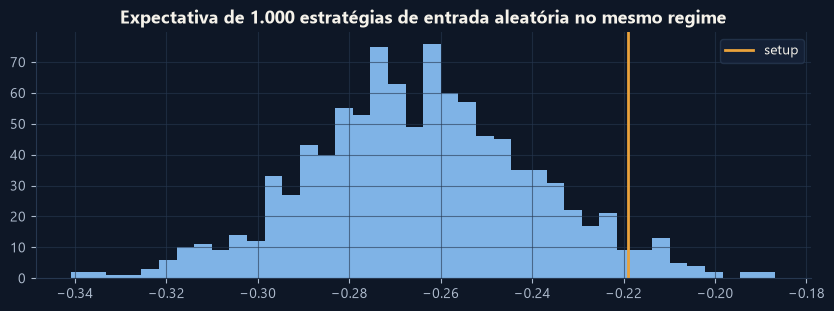

In [13]:
regime = np.where(h4 == h1, h4, 0)
cand = np.flatnonzero((regime != 0) & A["pode"] & ~A["zerar"])
s_real = sinal_grupo(compra, venda, h4, h1, FILTRO_PADRAO)
n_sinais = int(np.count_nonzero(s_real & A["pode"]))
rng = np.random.default_rng(SEED)
sim = np.empty(N_SIM)
for i in range(N_SIM):
    s_ = np.zeros(len(IDX), np.int64)
    pos_ = rng.choice(cand, n_sinais, replace=False)
    s_[pos_] = regime[pos_]
    sim[i] = rodar(s_, saida_dir=h1)["R"].mean()
real = TR_PADRAO["R"].mean()
P_VALOR = (np.sum(sim >= real) + 1) / (N_SIM + 1)
print(
    f"Setup completo: {real:+.3f} R | aleatório: média {sim.mean():+.3f} R (5%–95%: {np.percentile(sim, 5):+.3f} a "
    f"{np.percentile(sim, 95):+.3f}) | p-valor = {P_VALOR:.3f}"
)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(sim, bins=40, color=CORES["secundaria"])
ax.axvline(real, color=CORES["primaria"], lw=2, label="setup")
ax.set_title("Expectativa de 1.000 estratégias de entrada aleatória no mesmo regime")
ax.legend()
plt.show()

## 9. Resultado fora da amostra (walk-forward) e quebras
É o número que vale para a aprovação: médias escolhidas só com o passado, custos completos.

,Walk-forward,Padrão fixo
Nº trades,856.000,910.000
Win rate %,27.103,29.780
Payoff,1.592,1.328
Expectativa R,-0.236,-0.198
Expectativa R sem custos,-0.011,0.025
Fator de lucro,0.592,0.563
Total R,-201.882,-180.459
Retorno % (1% risco),-87.527,-84.191
Máx. drawdown %,-87.424,-84.170
Sharpe,-3.170,-3.486


Referência buy & hold EURUSD no mesmo período: +6.3%


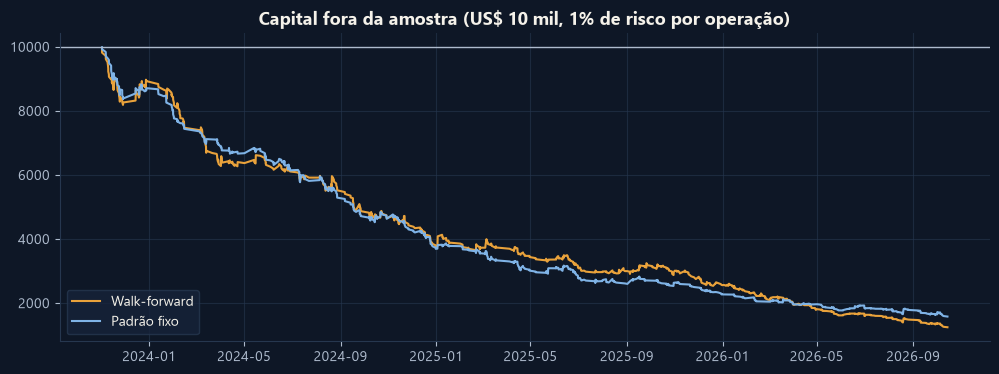

,trades,expectativa R,total R,máx. DD %
ano,,,,
2023,57,-0.190,-10.822,-17.462
2024,266,-0.317,-84.424,-57.367
2025,269,-0.135,-36.212,-38.576
2026,264,-0.267,-70.424,-52.076


,trades,expectativa R,total R
lado,,,
compra,432,-0.230,-99.432
venda,424,-0.242,-102.450


,trades,expectativa R,total R
sessao,,,
Londres (9–15h),499,-0.290,-144.681
Londres+NY (15–19h),272,-0.091,-24.735
NY tarde (19–21h),85,-0.382,-32.466


Zeradas no fim do dia: 92 (11%) | ainda no lucro ao zerar: 80% | R médio ao zerar: +1.15
Sensibilidade: com comissão de US$ 7/lote, a expectativa do padrão fixo fora da amostra vai de -0.198 para -0.271 R


In [14]:
ini_oos = pd.Timestamp(INICIO_OOS)
m_wf = metricas(TR_WF, ini_oos, FIM)
m_fixo_oos = metricas(TR_PADRAO, ini_oos, FIM)
bh = M15["fechamento"].loc[ini_oos:]
res_oos = pd.DataFrame({"Walk-forward": m_wf, "Padrão fixo": m_fixo_oos})
display(res_oos.round(3))
print(
    f"Referência buy & hold EURUSD no mesmo período: {(bh.iloc[-1] / bh.iloc[0] - 1) * 100:+.1f}%"
)

fig, ax = plt.subplots(figsize=(12, 4))
for nome, tr, cor in [
    ("Walk-forward", TR_WF, CORES["primaria"]),
    ("Padrão fixo", TR_PADRAO, CORES["secundaria"]),
]:
    t_ = tr[tr["entrada"] >= ini_oos].sort_values("saida")
    ax.plot(
        t_["saida"],
        10_000 * (1 + RISCO_POR_TRADE * t_["R"]).cumprod(),
        color=cor,
        label=nome,
    )
ax.axhline(10_000, color=CORES["texto_suave"], lw=1)
ax.set_title("Capital fora da amostra (US$ 10 mil, 1% de risco por operação)")
ax.legend()
plt.show()

t_ = TR_WF.assign(
    ano=TR_WF["entrada"].dt.year,
    lado=np.where(TR_WF["direcao"] == 1, "compra", "venda"),
    sessao=pd.cut(
        TR_WF["entrada"].dt.hour,
        [0, 15, 19, 24],
        right=False,
        labels=["Londres (9–15h)", "Londres+NY (15–19h)", "NY tarde (19–21h)"],
    ),
)


def dd_ano(r):
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    return (cap / cap.cummax() - 1).min() * 100


for col in ["ano", "lado", "sessao"]:
    q = t_.groupby(col, observed=True)["R"].agg(["count", "mean", "sum"])
    if col == "ano":
        q["máx. DD %"] = t_.groupby(col)["R"].apply(dd_ano)
    display(
        q.rename(
            columns={"count": "trades", "mean": "expectativa R", "sum": "total R"}
        ).round(3)
    )

fd = TR_WF[TR_WF["motivo"] == "fim do dia"]
print(
    f"Zeradas no fim do dia: {len(fd)} ({len(fd) / len(TR_WF):.0%}) | ainda no lucro ao zerar: {(fd['R'] > 0).mean():.0%} "
    f"| R médio ao zerar: {fd['R'].mean():+.2f}"
)
m_com = metricas(estrategia(comissao=7.0), ini_oos, FIM)
print(
    f"Sensibilidade: com comissão de US$ 7/lote, a expectativa do padrão fixo fora da amostra vai de "
    f"{m_fixo_oos['Expectativa R']:+.3f} para {m_com['Expectativa R']:+.3f} R"
)

## 10. Veredito
Aplicação mecânica dos critérios definidos no início.

In [ ]:
dd_anos = t_.groupby("ano")["R"].apply(dd_ano)
criterios = pd.DataFrame(
    [
        (
            "≥ 100 operações fora da amostra",
            f"{m_wf['Nº trades']:.0f}",
            m_wf["Nº trades"] >= 100,
        ),
        (
            "Expectativa > 0 R",
            f"{m_wf['Expectativa R']:+.3f}",
            m_wf["Expectativa R"] > 0,
        ),
        (
            "Fator de lucro > 1,2",
            f"{m_wf['Fator de lucro']:.2f}",
            m_wf["Fator de lucro"] > 1.2,
        ),
        ("Melhor que aleatório (p < 0,05)", f"p = {P_VALOR:.3f}", P_VALOR < 0.05),
        ("PBO < 0,5", f"{PBO:.2f}", PBO < 0.5),
        ("Nenhum ano com DD > 20%", f"pior {dd_anos.min():.1f}%", dd_anos.min() > -20),
        (
            f"≥ {MIN_TRADES_SEMANA:g} trades/semana e intervalo p90 ≤ {MAX_INTERVALO_P90} dias úteis",
            f"{m_wf['Trades/semana']:.1f}/sem · p90 {m_wf['Intervalo p90 (dias úteis)']:.0f}",
            (m_wf["Trades/semana"] >= MIN_TRADES_SEMANA)
            & (m_wf["Intervalo p90 (dias úteis)"] <= MAX_INTERVALO_P90),
        ),
    ],
    columns=["Critério", "Valor", "Passou"],
)
criterios["Passou"] = criterios["Passou"].map({True: "✅", False: "❌"})
display(criterios)
APROVADO = (criterios["Passou"] == "✅").all()
print(
    "VEREDITO:",
    "✅ APROVADO"
    if APROVADO
    else f"❌ REPROVADO ({(criterios['Passou'] == '❌').sum()} critério(s) falharam)",
)

,Critério,Valor,Passou
0,≥ 100 operações fora da amostra,856,✅
1,Expectativa > 0 R,-0.236,❌
2,"Fator de lucro > 1,2",0.59,❌
3,"Melhor que aleatório (p < 0,05)",p = 0.040,✅
4,"PBO < 0,5",0.77,❌
5,Nenhum ano com DD > 20%,pior -57.4%,❌
6,≥ 2 trades/semana e intervalo p90 ≤ 5 dias úteis,5.5/sem · p90 4,✅


VEREDITO: ❌ REPROVADO (4 critério(s) falharam)


## 11. Salvar os resultados
Pasta `backtests/002.1_pullback_saida_freq_EURUSD_H4-H1-M15/`: parâmetros, métricas, grade da otimização, blocos,
walk-forward, comparação de grupos e operações fora da amostra.

In [ ]:
PASTA = RAIZ / "backtests" / f"{BACKTEST_ID}_pullback_saida_freq_{SIMBOLO}_H4-H1-M15"
PASTA.mkdir(parents=True, exist_ok=True)
parametros = {
    "id": BACKTEST_ID,
    "base": "002",
    "simbolo": SIMBOLO,
    "timeframes": ["H4", "H1", "M15"],
    "tendencia": {
        "ema_padrao": EMA_TEND_PADRAO,
        "ema_media": EMA_MEDIA_TEND,
        "inclinacao_barras": INCLINACAO_BARRAS,
    },
    "pullback": {
        "padrao": PB_PADRAO,
        "barras_sem_toque": BARRAS_SEM_TOQUE,
        "novo_padrao": NOVO_PADRAO,
        "filtro_padrao": FILTRO_PADRAO,
    },
    "grade": {
        "tendencia": GRADE_TEND,
        "pullback": GRADE_PB,
        "regra_novo": GRADE_NOVO,
        "filtro": GRADE_FILTRO,
        "saida": GRADE_SAIDA,
    },
    "saida": {
        "trailing": "Chandelier",
        "k_padrao": K_TRAILING,
        "be_r_padrao": BE_R,
        "atr": ATR_PERIODO,
        "stop_folga_atr": STOP_FOLGA_ATR,
        "stop_min_max_atr": [STOP_MIN_ATR, STOP_MAX_ATR],
        "sai_se_h1_perder_tendencia": True,
    },
    "day_trade": {
        "sessao_fechamento": SESSAO,
        "hora_zerar": HORA_ZERAR,
        "horas_virada": HORAS_VIRADA,
        "mult_spread_virada": MULT_SPREAD_VIRADA,
    },
    "custos": {
        "slippage_pontos": SLIPPAGE_PONTOS,
        "comissao_usd_lote": COMISSAO_USD_LOTE,
    },
    "validacao": {
        "inicio_oos": INICIO_OOS,
        "treino_meses": TREINO_MESES,
        "teste_meses": TESTE_MESES,
        "n_blocos": N_BLOCOS,
        "n_sim": N_SIM,
        "seed": SEED,
        "pbo": round(PBO, 3),
        "p_valor": round(P_VALOR, 4),
    },
    "frequencia": {
        "min_trades_semana": MIN_TRADES_SEMANA,
        "max_intervalo_p90": MAX_INTERVALO_P90,
    },
    "dados": {"m15_de": f"{INI:%Y-%m-%d}", "m15_ate": f"{FIM:%Y-%m-%d}"},
    "aprovado": bool(APROVADO),
}
(PASTA / "parametros.json").write_text(
    json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8"
)
res_oos.round(4).to_csv(PASTA / "metricas_oos.csv", encoding="utf-8")
grade.round(4).to_csv(PASTA / "grade_otimizacao.csv", encoding="utf-8")
blocos.round(3).to_csv(PASTA / "blocos.csv", encoding="utf-8")
WF.round(4).to_csv(PASTA / "walkforward.csv", index=False, encoding="utf-8")
tab_g.round(4).to_csv(PASTA / "grupos.csv", encoding="utf-8")
TR_WF.round({"R": 4, "R_bruto": 4}).to_csv(
    PASTA / "operacoes_oos.csv", index=False, encoding="utf-8"
)
criterios.to_csv(PASTA / "criterios.csv", index=False, encoding="utf-8")
print(f"Resultados salvos em {PASTA}")

Resultados salvos em c:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\002.1_pullback_saida_freq_EURUSD_H4-H1-M15
